In [1]:
import scanpy as sc
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import anndata
from scipy.sparse import csr_matrix
import numpy as np
import os
from sklearn.metrics import pairwise_distances
from scipy.stats import chi2_contingency
from sklearn.decomposition import PCA
from matplotlib.ticker import MaxNLocator

sc.settings.verbosity = 3

In [2]:
root_path = r'G:\data\transcriptome\MERFISH'

adata_m = sc.read_h5ad(r'G:\data\transcriptome\MERFISH\MH_m_merfish_isocortex_neurons.h5ad',backed='r')
adata_m.obs.region_nolayer = adata_m.obs.region_nolayer.cat.add_categories(['CTX_others'])
adata_m.obs.region_nolayer = adata_m.obs.region_nolayer.fillna('CTX_others')
# adata_m[adata_m=='PL'] = 'PreL'
adata_h = sc.read_h5ad(r'G:\data\transcriptome\adata_h_to_bink.h5ad',backed='r')
df_bink_love = pd.read_csv(r'G:\data\transcriptome\MERFISH\sketch_object_cca_full_yzx.csv',index_col=0)
print(df_bink_love.shape)
df_h_cluster_lut = pd.read_excel(r'G:\data\transcriptome\Human\science.add7046_table_s3.xlsx')

df_h_dissection_region = pd.read_csv(r'E:\ZhixiYun\Projects\fMOST_atlas\Tables\celltype\human_transcriptome_brainregion.csv')
df_h_dissection_region = df_h_dissection_region[df_h_dissection_region.confidence==1]
df_h_dissection_region['Dissection'] = [f'Human {x}' for x in df_h_dissection_region['Dissection']]
lut_h_dissection_region = dict(zip(df_h_dissection_region.Dissection,df_h_dissection_region.region))
lut_h_region_dissection = dict(zip(df_h_dissection_region.region,df_h_dissection_region.Dissection))

c_mouse = np.array([29,140,67])/255.0
c_human = np.array([255,102,102])/255.0

(1814877, 50)


In [3]:
lut_region2lobe = {
    'Cuneus':'OL', 'Cuneus-Lingual':'OL', 'Fusiform':'TL', 'Inferior Frontal gyrus':'FL',
    'Inferior Temporal':'TL', 'Middle Frontal gyrus':'FL', 'Middle Temporal':'TL',
    'Parahippocampal':'TL', 'Postcentral':'PL', 'Posterior Cingulate':'CC', 'Precentral':'FL',
    'Rostral Anterior Cingulate':'CC', 'Superior Parietal':'PL', 'Superior Temporal':'TL',
    'Supramarginal':'PL', 'Transverse Temporal':'TL','Temporal Lobe':'TL'
}
lut_region2lobe_m = {
    'MOp': 'FL', 'MOs': 'FL', 'ORB': 'FL', 'FRP': 'FL',
    'SSp': 'PL', 'SSs': 'PL', 'PTLp': 'PL', 'VISC': 'PL',
    'AUDp': 'TL', 'AUDd': 'TL', 'AUDv': 'TL', 'AUDpo': 'TL',
    'PERI': 'TL', 'TEa': 'TL', 'ECT': 'TL', 'VISpor': 'TL',
    'AUD': 'TL', 'VIS': 'OL', 
    'ACA': 'CC', 'ILA': 'FL', 'PL': 'FL', 'GU': 'PL', 
    # 'AI': 'FL', 'RSP': 'PL'
}
homo_color_lut = {
    'OL':np.array([231,172,161])/255.0,
     'FL':np.array([255,206,72])/255.0,
     'PL':np.array([153,217,234])/255.0,
     'TL':np.array([118,137,211])/255.0,
    'CC':np.array([223,79,114])/255.0}

In [4]:
counts = csr_matrix(np.zeros(df_bink_love.shape, dtype=np.float32))
adata_bink_love = anndata.AnnData(counts)
adata_bink_love.obsm['X_umap'] = pd.read_csv(os.path.join(root_path,'sketch_object_umap_full_yzx.csv'), index_col=0).values
adata_bink_love.obs = pd.read_csv(os.path.join(root_path, 'sketch_object_meta_data_yzx.csv'))

adata_bink_love.obsm['X_cca'] = df_bink_love.values
adata_bink_love.obs_names = df_bink_love.index
# adata_bink_love.obs['species'] = ['mouse' if x.find(':')==-1 else 'human' for x in adata_bink_love.obs_names]
adata_bink_love.obs['brain_region_old'] = None
adata_bink_love.obs.loc[adata_bink_love.obs[adata_bink_love.obs.species=='mouse'].index,'brain_region_old'] = adata_m.obs.loc[adata_bink_love.obs[adata_bink_love.obs.species=='mouse'].index].region_nolayer
adata_bink_love.obs.loc[adata_bink_love.obs[adata_bink_love.obs.brain_region_old=='ORB'].index,'brain_region_old'] = adata_m.obs.loc[adata_bink_love.obs[adata_bink_love.obs.brain_region_old=='ORB'].index].region_roi

adata_bink_love.obs.loc[adata_bink_love.obs[adata_bink_love.obs.species=='human'].index,'brain_region_old'] = adata_h.obs.loc[adata_bink_love.obs[adata_bink_love.obs.species=='human'].index].roi
adata_bink_love.obs['brain_region'] = adata_bink_love.obs['brain_region_old'].copy()
adata_bink_love.obs.loc[adata_bink_love.obs[adata_bink_love.obs.species=='human'].index,'brain_region'] = adata_h.obs.loc[adata_bink_love.obs[adata_bink_love.obs.species=='human'].index].roi.map(lut_h_dissection_region)

adata_bink_love.obs['celltype.full'] = adata_bink_love.obs['celltype.full'].astype(str)


adata_bink_love.obs.loc[adata_bink_love.obs['species']=='mouse','lobe'] = adata_bink_love.obs.loc[adata_bink_love.obs['species']=='mouse', 'brain_region'].map(lut_region2lobe_m.get)
adata_bink_love.obs.loc[adata_bink_love.obs['species']=='human','lobe'] = adata_bink_love.obs.loc[adata_bink_love.obs['species']=='human', 'brain_region'].map(lut_region2lobe.get)

# adata_bink_love = adata_bink_love[~adata_bink_love.obs['cca_clusters'].isnull()].copy()
# adata_bink_love.obsm['X_umap'] = pd.read_csv(os.path.join(root_path,'sketch_object_umap_cca_yzx.csv'), index_col=0).loc[adata_bink_love.obs_names].values

adata_bink_love.obsm['X_umap'] = pd.read_csv(os.path.join(root_path,'umap_by_scanpy.csv'), index_col=0).loc[adata_bink_love.obs_names].values


In [5]:
adata_bink_love.obs.species.value_counts()

species
mouse    1166147
human     648730
Name: count, dtype: int64

In [ ]:
# Run this cell to generate umap embeddings (time consuming)

# sc.pp.neighbors(adata_bink_love, n_neighbors=20, n_pcs=10, use_rep = "X_cca")
# sc.tl.umap(adata_bink_love)
# # sc.pl.umap(adata_bink_love, color=["species"])

# # save umap embeddings as csv
# pd.DataFrame(adata_bink_love.obsm['X_umap'], index=adata_bink_love.obs_names, columns=['UMAP1','UMAP2']).to_csv(os.path.join(root_path,'umap_by_scanpy.csv'))

In [7]:
df_m_metadata_cluster = pd.read_csv(os.path.join(root_path,'MH_m_merfish_isocortex_neurons_obs.csv'), index_col=0)
df_m_metadata_cluster.columns

Index(['organism_ontology_term_id', 'donor_id',
       'development_stage_ontology_term_id', 'sex_ontology_term_id',
       'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id',
       'tissue_ontology_term_id', 'cell_type_ontology_term_id',
       'assay_ontology_term_id', 'suspension_type', 'cluster_id_transfer',
       'subclass_transfer', 'cluster_confidence_score',
       'subclass_confidence_score', 'high_quality_transfer',
       'major_brain_region', 'ccf_region_name', 'brain_section_label',
       'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease',
       'organism', 'sex', 'tissue', 'self_reported_ethnicity',
       'development_stage', 'observation_joinid', 'region', 'region_nolayer',
       'region_roi', 'rough_region'],
      dtype='object')

In [8]:
mouse_cell_obs_name = adata_bink_love.obs_names[adata_bink_love.obs['species']=='mouse']
adata_bink_love.obs.loc[mouse_cell_obs_name,'celltype'] = df_m_metadata_cluster.loc[mouse_cell_obs_name].subclass_transfer
adata_bink_love.obs.loc[mouse_cell_obs_name,'celltype_sub'] = df_m_metadata_cluster.loc[mouse_cell_obs_name][['subclass_transfer','cluster_id_transfer']].astype(str).agg('_'.join, axis=1)

In [9]:
df_h_cluster_lut = pd.read_excel(r'G:\data\transcriptome\Human\science.add7046_table_s3.xlsx')
df_h_cluster_lut = df_h_cluster_lut.dropna(how='all')

homo_color_lut = {
    # 'OL':np.array([231,172,161])/255.0,
                 'FL':np.array([255,206,72])/255.0,
                 'PL':np.array([153,217,234])/255.0,
                 'TL':np.array([118,137,211])/255.0}

fullname_acronym_lut = np.array(
[['Amygdala', 'Amygdala'],
 ['Basal forebrain', 'Basal_forebrain'],
 ['Cerebellum', 'CB'],
 ['Cerebral cortex', 'CTX'],
 ['Hippocampus', 'HPF'],
 ['Hypothalamus', 'HY'],
 ['Medulla', 'MY'],
 ['Midbrain', 'MB'],
 ['Pons', 'P'],
 ['Spinal cord', 'Spinal_cord'],
 ['Thalamus', 'TH']]
)
fullname_acronym_lut = dict(zip(fullname_acronym_lut[:,0],fullname_acronym_lut[:,1]))

In [10]:
cluster_id_annotation_lut = {}
for i in range(df_h_cluster_lut.shape[0]):
    CID,s1,s2=df_h_cluster_lut.iloc[i][['Cluster ID','Transferred MTG Label','Neurotransmitter auto-annotation']]
    acronym = df_h_cluster_lut.iloc[i]['Top three regions'].split(':')[0]
    acronym = fullname_acronym_lut[acronym]
    if not isinstance(s2,str):
        if np.isnan(s2):
            s2 = ''
    flag_gaba = False
    flag_glut = False
    new_s2 = []
    for tmp_s in s2.split(' '):
        if tmp_s=='': continue
        if not flag_glut:
            if tmp_s.find('VGLUT')!=-1:
                new_s2.append('Glut')
                flag_glut = True
        if not flag_gaba:
            if tmp_s.find('GABA')!=-1:
                flag_gaba = True
                new_s2.append('Gaba')
        if tmp_s.find('GABA')==-1 and tmp_s.find('VGLUT')==-1:
            new_s2.append(tmp_s)
            
    new_s2 = "-".join(new_s2)
        
    if np.isnan(CID): continue
    if not isinstance(s1,str):
        if np.isnan(s1):
            cluster_id_annotation_lut[int(CID)] = f'{new_s2}'
    else:
        if s1.startswith('L') and not s1.startswith('Lamp'):
            # print(s1)
            cluster_id_annotation_lut[int(CID)] = f'{s1} {acronym} {new_s2}'
        else:
            cluster_id_annotation_lut[int(CID)] = f'{s1} {new_s2}'
            
            

In [11]:
human_cell_obs_name = adata_bink_love.obs_names[adata_bink_love.obs['species']=='human']
adata_bink_love.obs.loc[human_cell_obs_name,'celltype'] = adata_h.obs.loc[human_cell_obs_name].cluster_id.map(cluster_id_annotation_lut)
adata_bink_love.obs.loc[human_cell_obs_name, 'celltype_sub'] = (
    adata_bink_love.obs.loc[human_cell_obs_name, 'celltype'].astype(str) + '_' + 
    adata_h.obs.loc[human_cell_obs_name]['subcluster_id'].astype(str)
)

In [12]:
intersection = np.intersect1d(adata_bink_love.obs[adata_bink_love.obs.species=='mouse'].celltype,adata_bink_love.obs[adata_bink_love.obs.species=='human'].celltype)
intersection,intersection.shape
concat_dict = {'L4 IT CTX Glut':'L4/5 IT CTX Glut',
'L5 IT CTX Glut':'L4/5 IT CTX Glut',
'L5 NP CTX Glut':'L5/6 NP CTX Glut',}
intersection = np.union1d(intersection,list(concat_dict.keys()))
intersection = np.union1d(intersection,list(concat_dict.values()))

In [13]:
# tmpdf = adata_bink_love.obs[adata_bink_love.obs['celltype'].isin(intersection)].copy()
tmpdf = adata_bink_love.obs.copy()

tmpdf['count'] = 1


df_pivot = pd.pivot_table(tmpdf,values='count',index=['species','brain_region'],columns='celltype',aggfunc='sum',observed=True,fill_value=0).astype(float)

df_pivot = df_pivot[intersection]

for k,v in concat_dict.items():
    df_pivot[v] = df_pivot[k]+df_pivot[v]
droplist = list(concat_dict.keys())
for species in df_pivot.index.levels[0]:
    col = df_pivot.columns[np.argwhere(df_pivot.loc[[species]].sum(axis=0).values==0).flatten()[0]]
    if col not in droplist:
        droplist.append(col)
df_pivot = df_pivot.drop(columns=droplist)
print(df_pivot.shape)

(35, 12)


In [14]:

adata_bink_love.obs['concat_celltype'] = adata_bink_love.obs['celltype']
for ind in adata_bink_love.obs.index:
    ct = adata_bink_love.obs.loc[ind,'celltype']
    if ct in concat_dict:
        adata_bink_love.obs.loc[ind,'concat_celltype']=concat_dict[ct]        
adata_bink_love.obs.loc[~adata_bink_love.obs['concat_celltype'].isin(df_pivot.columns),'concat_celltype']=None

# adata_bink_love.obs.concat_celltype = adata_bink_love.obs.concat_celltype.cat.remove_unused_categories()

d:\anaconda3\envs\gene\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
d:\anaconda3\envs\gene\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
d:\anaconda3\envs\gene\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
d:\anaconda3\envs\gene\lib\site-packages\scanpy\plot

<Axes: title={'center': 'celltype.full'}, xlabel='UMAP1', ylabel='UMAP2'>

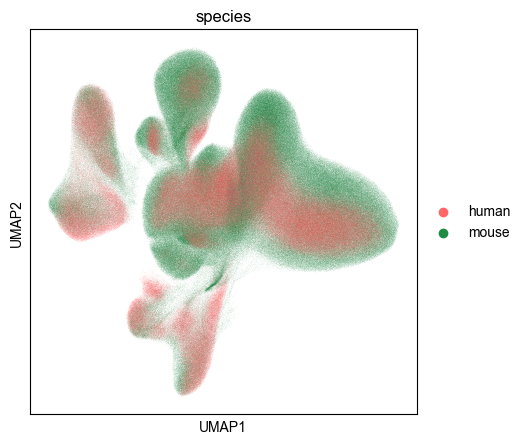

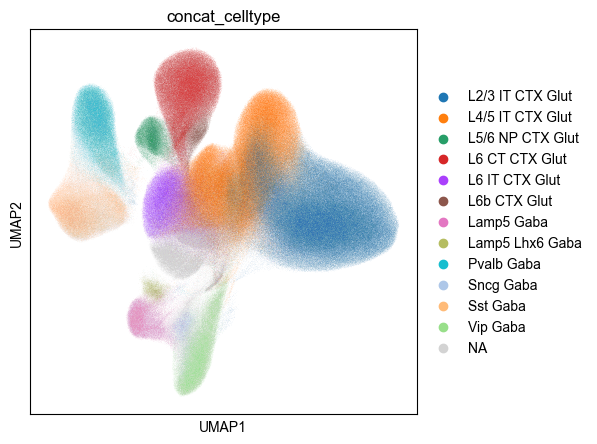

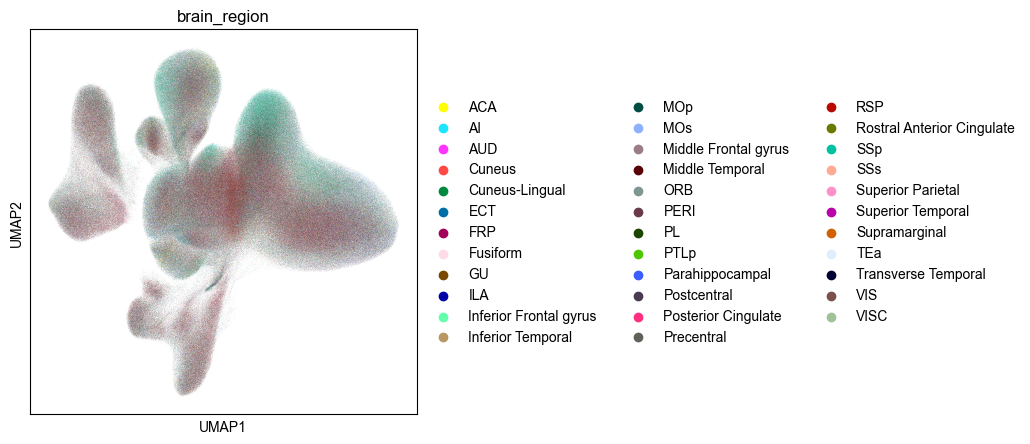

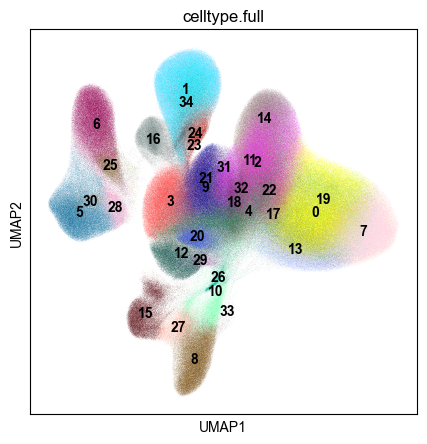

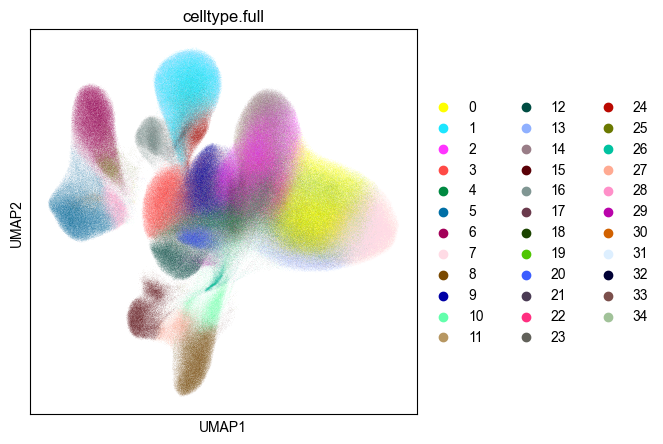

In [15]:
# need to use vector_friendly mode if saving SVG.
# sc.set_figure_params(vector_friendly=True)

show = False

fig,ax = plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata_bink_love,color='species',ax=ax,show=show,palette=[c_human,c_mouse],)
# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\umap_integration_species.svg', bbox_inches='tight', dpi=500)
fig,ax = plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata_bink_love,color='concat_celltype',ax=ax,show=show)
# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\umap_concat_celltype.svg', bbox_inches='tight', dpi=500)
fig,ax = plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata_bink_love, color="brain_region",ax=ax,show=show)
# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\umap_integration_brain_region.svg', bbox_inches='tight', dpi=500)
fig,ax = plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata_bink_love, color="celltype.full", legend_loc="on data",ax=ax,show=show)
# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\umap_integration_leiden.svg', bbox_inches='tight', dpi=500)
fig,ax = plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata_bink_love, color="celltype.full", ax=ax,show=show)
# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\umap_integration_leiden_legend.svg', bbox_inches='tight', dpi=500)

# sc.set_figure_params(vector_friendly=False)



In [16]:
def js_divergence(arr1, arr2):
    def kl_divergence(mu1, cov1, mu2, cov2):
        # Ensure the covariance matrices are invertible
        cov2_inv = np.linalg.inv(cov2)
        
        # Dimensionality of the data
        k = mu1.shape[0]
        
        # Compute the KL divergence
        kl_div = 0.5 * (np.log(np.linalg.det(cov2) / np.linalg.det(cov1))
                        - k
                        + np.trace(cov2_inv @ cov1)
                        + (mu2 - mu1).T @ cov2_inv @ (mu2 - mu1))
        
        return kl_div

    # Compute means and covariances for both distributions
    mu1 = np.mean(arr1, axis=0)
    mu2 = np.mean(arr2, axis=0)
    cov1 = np.cov(arr1.T)
    cov2 = np.cov(arr2.T)

    # Compute the midpoint distribution's parameters
    mu_m = 0.5 * (mu1 + mu2)
    cov_m = 0.5 * (cov1 + cov2)

    # Calculate the JS divergence
    js_div = 0.5 * kl_divergence(mu1, cov1, mu_m, cov_m) + 0.5 * kl_divergence(mu2, cov2, mu_m, cov_m)
    
    return js_div


print('human')
for lobe_pair in [['FL','PL'],['FL','TL'],['PL','TL']]:
    arr1 = adata_bink_love.obsm['X_cca'][(adata_bink_love.obs['species']=='human') & (adata_bink_love.obs['lobe']==lobe_pair[0])]
    arr2 = adata_bink_love.obsm['X_cca'][(adata_bink_love.obs['species']=='human') & (adata_bink_love.obs['lobe']==lobe_pair[1])]
    jsd = js_divergence(arr1,arr2)
    print(lobe_pair, jsd)
    
print('mouse')
for lobe_pair in [['FL','PL'],['FL','TL'],['PL','TL']]:
    arr1 = adata_bink_love.obsm['X_cca'][(adata_bink_love.obs['species']=='mouse') & (adata_bink_love.obs['lobe']==lobe_pair[0])]
    arr2 = adata_bink_love.obsm['X_cca'][(adata_bink_love.obs['species']=='mouse') & (adata_bink_love.obs['lobe']==lobe_pair[1])]
    jsd = js_divergence(arr1,arr2)
    print(lobe_pair, jsd)


human
['FL', 'PL'] 0.5122506729770151
['FL', 'TL'] 0.7515380910105112
['PL', 'TL'] 0.2898331782719816
mouse
['FL', 'PL'] 0.789599130092754
['FL', 'TL'] 0.8388480497073487
['PL', 'TL'] 0.822540157802075


C:\Users\user\AppData\Local\Temp\ipykernel_21004\2298649027.py:8: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_conf_map = pd.pivot_table(tmpobs, values='count', index='concat_celltype',columns='celltype.full',aggfunc='sum',dropna=False)


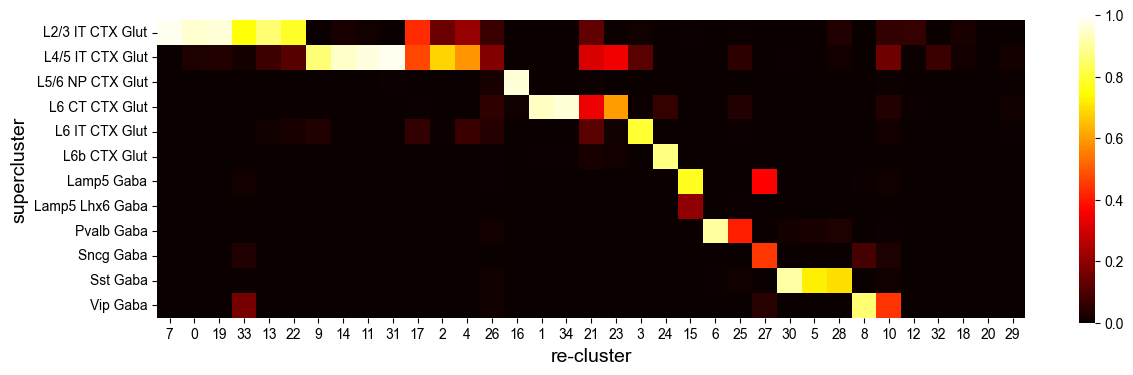

In [17]:
# Ensure both columns are of the same data type
celltype_full = adata_bink_love.obs['celltype.full'].copy().astype(str)
concat_celltype = adata_bink_love.obs['concat_celltype'].copy().astype(str)

tmpobs = adata_bink_love.obs.copy()
tmpobs['count'] = 1

df_conf_map = pd.pivot_table(tmpobs, values='count', index='concat_celltype',columns='celltype.full',aggfunc='sum',dropna=False)
df_conf_map = df_conf_map/df_conf_map.sum(axis=0)
df_conf_map = df_conf_map.drop(index=np.nan)
resort_xticklabels= ['7', '0', '19', '33', '13', '22',
                    '9', '14', '11', '31', '17', '2', '4','26',
                    '16',
                    '1', '34', '21', '23',
                    '3',
                    '24',
                    '15',
                    '6','25',
                    '27',
                    '30', '5', '28',
                    '8','10',
                    '12','32','18', '20','29']
df_conf_map = df_conf_map[resort_xticklabels]
plt.figure(figsize=(14,4))
g=sns.heatmap(df_conf_map,cmap='hot',square=True,vmin=0,vmax=1,annot=False)
plt.xlabel('re-cluster',fontsize=14)
plt.ylabel('supercluster',fontsize=14)
# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\confusion_matrix.png', bbox_inches='tight', dpi=300)
plt.show()

# df_conf_map.to_csv(r'E:\ZhixiYun\Projects\fMOST_atlas\Tables\source_data\EDF_cross_cell_type_confusion_matrix_merfish.csv')

In [18]:
mouse_cell_obs_name = adata_bink_love.obs_names[adata_bink_love.obs.species=='mouse']
human_cell_obs_name = adata_bink_love.obs_names[adata_bink_love.obs.species=='human']
df_all_cells = pd.DataFrame(index=list(mouse_cell_obs_name)+list(human_cell_obs_name))

df_all_cells.loc[mouse_cell_obs_name,'celltype'] = df_m_metadata_cluster.loc[mouse_cell_obs_name].subclass_transfer
df_all_cells.loc[mouse_cell_obs_name,'species'] = 'mouse'
df_all_cells.loc[mouse_cell_obs_name,'brain_region'] = adata_m.obs.loc[mouse_cell_obs_name,'region_nolayer'].astype('str')
df_all_cells.loc[mouse_cell_obs_name,'celltype_sub'] = adata_bink_love.obs.loc[mouse_cell_obs_name,'celltype_sub']

df_all_cells.loc[human_cell_obs_name,'celltype'] = adata_h.obs.loc[human_cell_obs_name].cluster_id.map(cluster_id_annotation_lut)
df_all_cells.loc[human_cell_obs_name,'MTG_celltype'] = adata_h.obs.loc[human_cell_obs_name].cluster_id.map(dict(zip(df_h_cluster_lut['Cluster ID'], df_h_cluster_lut['Transferred MTG Label'])))
df_all_cells.loc[human_cell_obs_name,'species'] = 'human'
df_all_cells.loc[human_cell_obs_name,'brain_region'] = [lut_h_dissection_region[x] for x in adata_h.obs.loc[human_cell_obs_name,'roi'].astype('str')]
df_all_cells.loc[human_cell_obs_name,'celltype_sub'] = adata_bink_love.obs.loc[human_cell_obs_name]['celltype_sub']


tmp = adata_bink_love.obs[adata_bink_love.obs.species=='mouse'].celltype.value_counts().sort_index()
# for ind in df_h_cluster_lut['Transferred MTG Label'].value_counts().index:
#     tmptmp = tmp[tmp.index.str.contains(ind)]
#     if len(tmptmp)==0 or tmptmp.sum()==0: continue
#     print(ind)
#     print(np.array(tmptmp.index))
#     print('--------------------------------')

mouse_MTG_substring = []
for ind in tmp.index:
    output_str = None
    if ind.startswith('L2/3 IT'):
        output_str = 'L2/3 IT'
    elif ind.startswith('Pvalb'):
        output_str = 'Pvalb'
    elif ind.startswith('Sst'):
        output_str = 'Sst'
    elif ind.startswith('Vip'):
        output_str = 'Vip'
    elif ind.startswith('L6b '):
        output_str = 'L6b'
    elif ind.startswith('Lamp5 Lhx6'):
        output_str = 'Lamp5 Lhx6'
    elif ind.startswith('L5 IT'):
        output_str = 'L5 IT'
    elif ind.startswith('Lamp5 Gaba'):
        output_str = 'Lamp5'
    elif ind.startswith('L6 IT'):
        output_str = 'L6 IT'
    elif ind.startswith('Sncg'):
        output_str = 'Sncg'
    elif ind.startswith('L6 CT'):
        output_str = 'L6 CT'
    mouse_MTG_substring.append(output_str)
mouse_ct_MTG_lut = dict(zip(tmp.index, mouse_MTG_substring))
    
df_all_cells.loc[mouse_cell_obs_name,'MTG_celltype'] = df_m_metadata_cluster.loc[mouse_cell_obs_name].subclass_transfer.map(mouse_ct_MTG_lut)



In [19]:
intersection = np.intersect1d(df_all_cells[df_all_cells.species=='mouse'].celltype,df_all_cells[df_all_cells.species=='human'].celltype)
concat_dict = {'L4 IT CTX Glut':'L4/5 IT CTX Glut',
'L5 IT CTX Glut':'L4/5 IT CTX Glut',
'L5 NP CTX Glut':'L5/6 NP CTX Glut',}
intersection = np.union1d(intersection,list(concat_dict.keys()))
intersection = np.union1d(intersection,list(concat_dict.values()))
print(intersection,intersection.shape)

intersection_MTG = np.intersect1d(df_all_cells[df_all_cells.species=='mouse']['MTG_celltype'].dropna(),df_all_cells[df_all_cells.species=='human']['MTG_celltype'].dropna())
print(intersection_MTG,intersection_MTG.shape)


['L2/3 IT CTX Glut' 'L4 IT CTX Glut' 'L4/5 IT CTX Glut' 'L5 IT CTX Glut'
 'L5 NP CTX Glut' 'L5/6 NP CTX Glut' 'L6 CT CTX Glut' 'L6 IT CTX Glut'
 'L6b CTX Glut' 'Lamp5 Gaba' 'Lamp5 Lhx6 Gaba' 'Pvalb Gaba' 'Sncg Gaba'
 'Sst Gaba' 'Vip Gaba'] (15,)
['L2/3 IT' 'L5 IT' 'L6 CT' 'L6 IT' 'L6b' 'Lamp5' 'Lamp5 Lhx6' 'Pvalb'
 'Sncg' 'Sst' 'Vip'] (11,)


(35, 12)


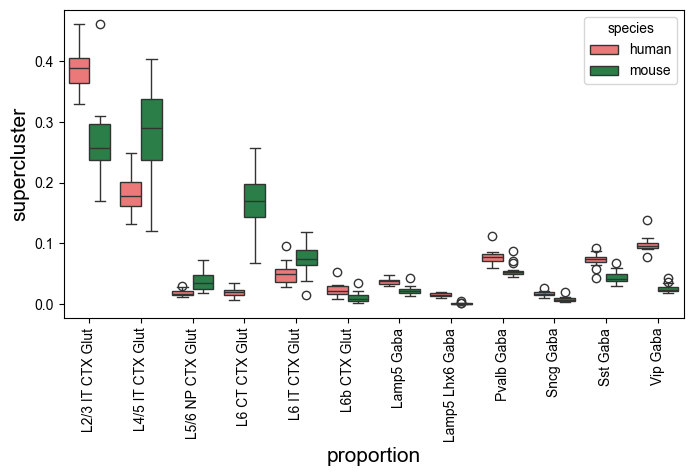

In [20]:
# tmpdf = adata_bink_love.obs[adata_bink_love.obs['celltype'].isin(intersection)].copy()
tmpdf = df_all_cells.copy()

tmpdf['count'] = 1

concat_dict = {'L4 IT CTX Glut':'L4/5 IT CTX Glut',
'L5 IT CTX Glut':'L4/5 IT CTX Glut',
'L5 NP CTX Glut':'L5/6 NP CTX Glut',}

df_pivot = pd.pivot_table(tmpdf,values='count',index=['species','brain_region'],columns='celltype',aggfunc='sum',observed=True,fill_value=0).astype(float)
df_pivot = df_pivot.sort_index()
intersection = np.union1d(intersection,list(concat_dict.keys()))
intersection = np.union1d(intersection,list(concat_dict.values()))
df_pivot = df_pivot[intersection]

for k,v in concat_dict.items():
    df_pivot[v] = df_pivot[k]+df_pivot[v]
droplist = list(concat_dict.keys())
for species in df_pivot.index.levels[0]:
    col = df_pivot.columns[np.argwhere(df_pivot.loc[[species]].sum(axis=0).values==0).flatten()[0]]
    if col not in droplist:
        droplist.append(col)
df_pivot = df_pivot.drop(columns=droplist)

# df_pivot = df_pivot[df_pivot.columns[df_pivot.columns.str.contains('Glut')]]

print(df_pivot.shape)
df_pivot = df_pivot.div(df_pivot.sum(axis=1),axis=0)
df_flattened = df_pivot.reset_index().melt(id_vars=['species', 'brain_region'], var_name='supercluster', value_name='proportion')
df_flattened['species'] = df_flattened['species']
df_flattened = df_flattened[['proportion', 'species', 'supercluster']]
plt.figure(figsize=(8,4))
sns.boxplot(data=df_flattened, x='supercluster', y='proportion', hue='species',palette={'mouse':c_mouse,'human':c_human})
plt.xticks(rotation=90)
plt.ylabel('supercluster',fontsize=15)
plt.xlabel('proportion',fontsize=15)
# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\supercluster_proportion_v.png', bbox_inches='tight', dpi=300)
plt.show()

# df_flattened.to_csv(r'E:\ZhixiYun\Projects\fMOST_atlas\Tables\source_data\EDF_supercluster_proportion_boxplot_merfish.csv', index=False)


In [21]:
df_flattened[['species','supercluster']].value_counts()

species  supercluster    
mouse    L2/3 IT CTX Glut    19
         L4/5 IT CTX Glut    19
         Sst Gaba            19
         Sncg Gaba           19
         Pvalb Gaba          19
         Lamp5 Lhx6 Gaba     19
         Lamp5 Gaba          19
         L6b CTX Glut        19
         L6 IT CTX Glut      19
         L6 CT CTX Glut      19
         L5/6 NP CTX Glut    19
         Vip Gaba            19
human    L4/5 IT CTX Glut    16
         Vip Gaba            16
         Sst Gaba            16
         Sncg Gaba           16
         Pvalb Gaba          16
         Lamp5 Lhx6 Gaba     16
         Lamp5 Gaba          16
         L6b CTX Glut        16
         L6 IT CTX Glut      16
         L6 CT CTX Glut      16
         L5/6 NP CTX Glut    16
         L2/3 IT CTX Glut    16
Name: count, dtype: int64

In [22]:
tmpdf = adata_bink_love.obs.copy()
tmpdf = tmpdf[tmpdf['lobe'].isin(['FL','PL','TL','OL'])]
tmpdf = tmpdf[tmpdf['celltype'].isin(intersection)]

tmpdf['count']=1
df_pivot_leiden_ori = pd.pivot_table(tmpdf,values='count',index=['species','lobe'],columns='celltype.full',aggfunc='sum',observed=True,fill_value=0).astype(float)
df_pivot_leiden_ori = df_pivot_leiden_ori.sort_index()
print(df_pivot_leiden_ori.shape)


thresh_ratio = 0.0001

print('h',np.sum(tmpdf['species']=='human')*thresh_ratio)
print('m',np.sum(tmpdf['species']=='mouse')*thresh_ratio)

df_pivot_leiden_ori = df_pivot_leiden_ori[df_pivot_leiden_ori.loc[['human']].sum(axis=0)[df_pivot_leiden_ori.loc[['human']].sum(axis=0)>np.sum(tmpdf['species']=='human')*thresh_ratio].index]
df_pivot_leiden_ori = df_pivot_leiden_ori[df_pivot_leiden_ori.loc[['mouse']].sum(axis=0)[df_pivot_leiden_ori.loc[['mouse']].sum(axis=0)>np.sum(tmpdf['species']=='mouse')*thresh_ratio].index]
print(df_pivot_leiden_ori.shape)
# df_pivot_leiden_ori.to_csv(r'G:\data\transcriptome\MERFISH\homo_similarity_lobe_yzx.csv')


chi2_h,p_h,dof_h,expected_h =chi2_contingency(df_pivot_leiden_ori.loc['human'].values)
Ro_e_h = df_pivot_leiden_ori.loc['human']/expected_h
row_sort_idx_h = np.argsort(Ro_e_h)
chi2_m,p_m,dof_m,expected_m =chi2_contingency(df_pivot_leiden_ori.loc['mouse'].values)
Ro_e_m = df_pivot_leiden_ori.loc['mouse']/expected_m
row_sort_idx_m = np.argsort(Ro_e_m)
Ro_e = pd.concat([Ro_e_h,Ro_e_m])
row_sort_idx = np.vstack([row_sort_idx_h,row_sort_idx_m])



df_pivot_leiden = df_pivot_leiden_ori.copy()
df_pivot_leiden = df_pivot_leiden.div(df_pivot_leiden.sum(axis=1),axis=0)
# df_pivot_leiden.loc[['human']] = (df_pivot_leiden.loc[['human']]-df_pivot_leiden.loc[['human']].mean(axis=0))/df_pivot_leiden.loc[['human']].std(axis=0)
# df_pivot_leiden.loc[['mouse']] = (df_pivot_leiden.loc[['mouse']]-df_pivot_leiden.loc[['mouse']].mean(axis=0))/df_pivot_leiden.loc[['mouse']].std(axis=0)
# df_pivot_leiden = (df_pivot_leiden-df_pivot_leiden.mean(axis=0))/df_pivot_leiden.std(axis=0)
# df_pivot_leiden = df_pivot_leiden.dropna(how='any',axis=0)
# df_pivot_leiden.drop(('mouse','AI'), inplace=True)
# df_pivot_leiden.drop(('mouse','GU'), inplace=True)
# df_pivot_leiden.drop(('human','Cuneus-Lingual'), inplace=True)
# df_pivot_leiden.to_csv(r'G:\data\transcriptome\homo_similarity_yzx.csv')


(8, 35)
h 48.554100000000005
m 84.39840000000001
(8, 26)


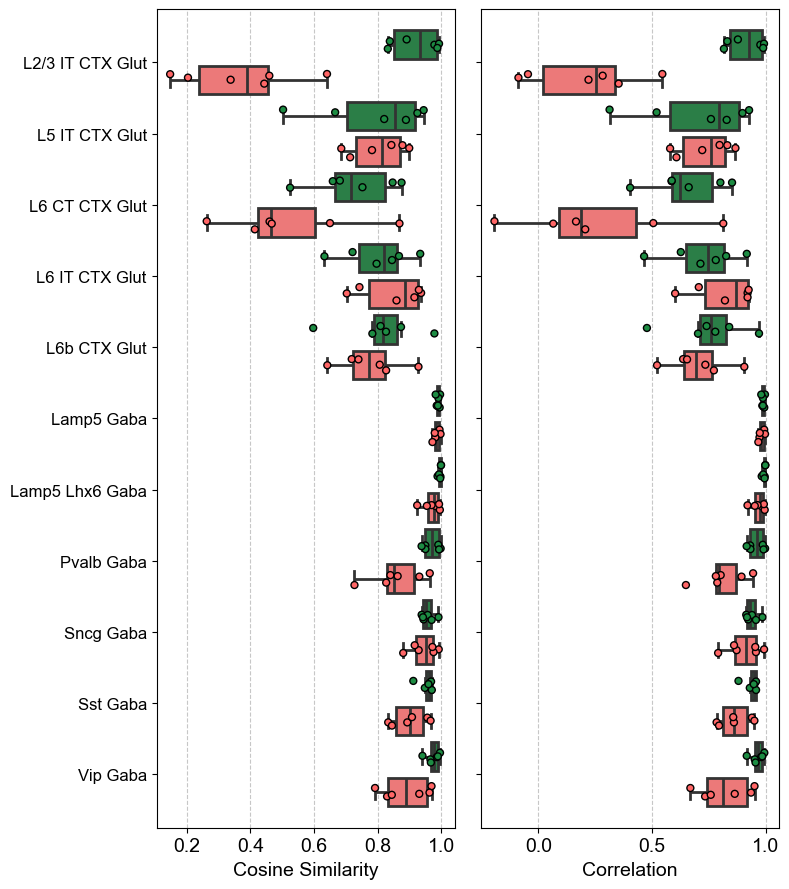

In [23]:

tmpdf = adata_bink_love.obs.copy()
tmpdf = tmpdf[tmpdf['lobe'].isin(['FL','PL','TL','OL'])]
tmpdf = tmpdf[tmpdf['celltype'].isin(['L2/3 IT CTX Glut', 'L5 IT CTX Glut', 
                  'L6 CT CTX Glut', 'L6 IT CTX Glut', 'L6b CTX Glut',
                  'Lamp5 Gaba', 'Lamp5 Lhx6 Gaba', 'Pvalb Gaba', 'Sncg Gaba',
                  'Sst Gaba', 'Vip Gaba'])]

tmpdf['count']=1
df_pivot_leiden_ori = pd.pivot_table(tmpdf,values='count',index=['species','lobe'],columns=['celltype','celltype_sub'],aggfunc='sum',observed=True,fill_value=0).astype(float)
df_pivot_leiden_ori = df_pivot_leiden_ori.sort_index()

corr_m_mean_list = []
corr_h_mean_list = []
cosine_m_mean_list = []
cosine_h_mean_list = []

corr_m_list = []
corr_h_list = []
cosine_m_list = []
cosine_h_list = []

ct_list = []

for i, ct in enumerate(df_pivot_leiden_ori.columns.get_level_values(0).unique().to_numpy()):
    df_pivot_leiden_ori_sub = df_pivot_leiden_ori[ct].copy()
    
    if df_pivot_leiden_ori_sub.shape[1]<2:
        continue
    
    df_pivot_leiden_ori_sub_m = df_pivot_leiden_ori_sub.loc['mouse']
    df_pivot_leiden_ori_sub_h = df_pivot_leiden_ori_sub.loc['human']
    
    
    df_pivot_leiden_ori_sub_m = df_pivot_leiden_ori_sub_m[df_pivot_leiden_ori_sub_m.sum(axis=0)[df_pivot_leiden_ori_sub_m.sum(axis=0)>0].index]
    df_pivot_leiden_ori_sub_h = df_pivot_leiden_ori_sub_h[df_pivot_leiden_ori_sub_h.sum(axis=0)[df_pivot_leiden_ori_sub_h.sum(axis=0)>0].index]

    df_pivot_leiden_ori_sub_m = df_pivot_leiden_ori_sub_m.div(df_pivot_leiden_ori_sub_m.sum(axis=1),axis=0)
    df_pivot_leiden_ori_sub_h = df_pivot_leiden_ori_sub_h.div(df_pivot_leiden_ori_sub_h.sum(axis=1),axis=0)

    
    corr_m = df_pivot_leiden_ori_sub_m.T.corr().values
    corr_m_triu = corr_m[np.triu(corr_m) == 0]
    corr_m_mean = corr_m_triu.mean()
    
    corr_h = df_pivot_leiden_ori_sub_h.T.corr().values
    corr_h_triu = corr_h[np.triu(corr_h) == 0]
    corr_h_mean = corr_h_triu.mean()
    
    cosine_m = 1 - pairwise_distances(df_pivot_leiden_ori_sub_m.values, metric='cosine')
    cosine_m_triu = cosine_m[np.triu(cosine_m) == 0]
    cosine_m_mean = cosine_m_triu.mean()
    
    cosine_h = 1 - pairwise_distances(df_pivot_leiden_ori_sub_h.values, metric='cosine')
    cosine_h_triu = cosine_h[np.triu(cosine_h) == 0]
    cosine_h_mean = cosine_h_triu.mean()
    
    corr_m_mean_list.append(corr_m_mean)
    corr_h_mean_list.append(corr_h_mean)
    cosine_m_mean_list.append(cosine_m_mean)
    cosine_h_mean_list.append(cosine_h_mean)
    
    corr_m_list.append(corr_m_triu)
    corr_h_list.append(corr_h_triu)
    cosine_m_list.append(cosine_m_triu)
    cosine_h_list.append(cosine_h_triu)
    
    ct_list.append(ct)

    
# Plot
fig, axs = plt.subplots(1, 2, sharey=True, tight_layout=True, figsize=(8, 9))
axs[0].set_xlabel('Cosine Similarity', fontsize=14)
axs[1].set_xlabel('Correlation', fontsize=14)

for j, (list_m, list_h) in enumerate(zip([cosine_m_list, corr_m_list], [cosine_h_list, corr_h_list])):
    ax = axs[j]
    data = []
    labels = []
    species = []
    for i, (m_values, h_values) in enumerate(zip(list_m, list_h)):
        data.extend(m_values)
        labels.extend([f"{ct_list[i]}_mouse"] * len(m_values))
        species.extend(['mouse'] * len(m_values))
        data.extend(h_values)
        labels.extend([f"{ct_list[i]}_human"] * len(h_values))
        species.extend(['human'] * len(h_values))
    
    palette = {'mouse': c_mouse, 'human': c_human}
    sns.boxplot(y=labels, x=data, ax=ax, hue=species, palette=palette, showfliers=False, linewidth=2, legend=False)
    np.random.seed(821)
    sns.stripplot(y=labels, x=data, ax=ax, hue=species, palette=palette, alpha=1, 
                  jitter=0.2, dodge=False, size=5, linewidth=1, edgecolor='black', legend=False)
    
    ax.set_yticks(np.arange(len(ct_list)) * 2 + 0.5)
    ax.set_yticklabels(ct_list, rotation=0, ha='right', fontsize=12)
    ax.set_ylim(len(ct_list) * 2,-1)

    # Set x-axis labels
    ax.tick_params(axis='x', labelsize=14)
    ax.grid(axis='x', linestyle='--', alpha=0.7)


# df_sourcedata = pd.DataFrame({
#     'celltype': labels,
#     'species': species,
#     'value': data
# }).to_csv(r'E:\ZhixiYun\Projects\fMOST_atlas\Tables\source_data\EDF_celltype_sub_corr_merfish.csv', index=False)

# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\celltype_corr_MERFISH_LOBE', dpi=300, bbox_inches='tight')

plt.show()

    

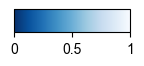

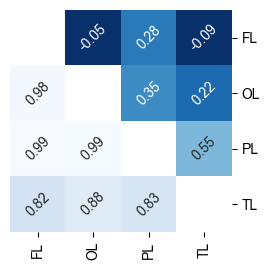

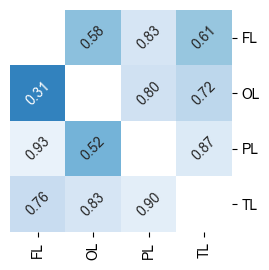

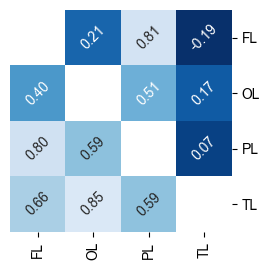

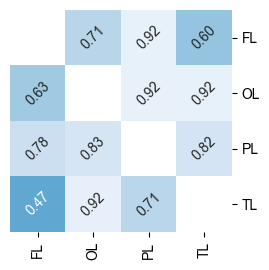

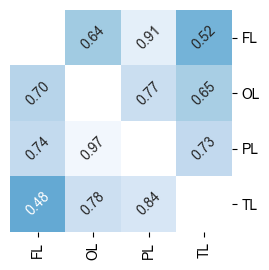

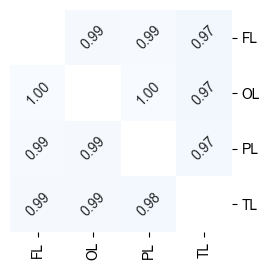

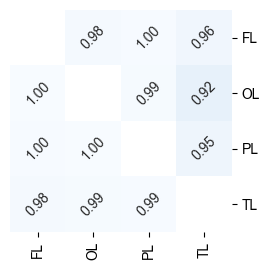

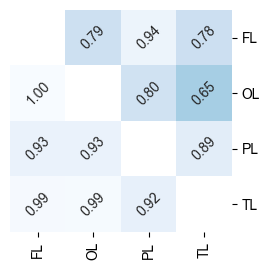

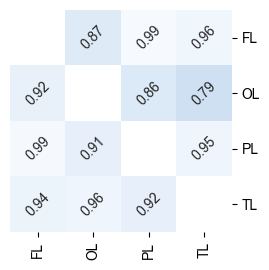

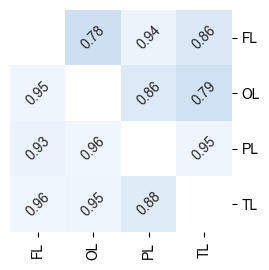

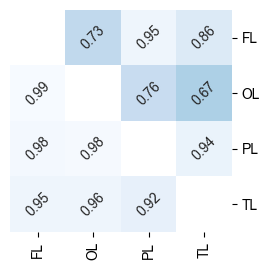

In [24]:
fig, cax = plt.subplots(figsize=(1.5, 0.3))
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap='Blues_r', norm=plt.Normalize(vmin=0, vmax=1)), cax=cax, orientation='horizontal')
cbar.set_ticks([0, 0.5, 1])
cbar.set_ticklabels(['0', '0.5', '1'])
# plt.savefig(r'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\celltype_corr\colorbar', dpi=300, bbox_inches='tight')
plt.show()

for j, (list_m, list_h) in enumerate(zip([corr_m_list], [corr_h_list])):
    for i in range(len(corr_h_list)):
        fig, ax = plt.subplots(1,1, tight_layout=True, figsize=(2.8, 2.8))
        heatmap_data = np.array([[0,corr_h_list[i][0],corr_h_list[i][1],corr_h_list[i][3]],
                                [corr_m_list[i][0],0,corr_h_list[i][2],corr_h_list[i][4]],
                                [corr_m_list[i][1],corr_m_list[i][2],0,corr_h_list[i][5]],
                                [corr_m_list[i][3],corr_m_list[i][4],corr_m_list[i][5],0]])
        mask = np.eye(heatmap_data.shape[0], dtype=bool)
        sns.heatmap(heatmap_data, cmap='Blues_r', annot=True, fmt='.2f', ax=ax, square=True,
                    cbar=False, mask=mask, vmin=0, vmax=1, annot_kws={'rotation': 45})
        ax.set_xticks(np.arange(4)+0.5)
        ax.set_xticklabels(df_pivot_leiden_ori.loc['human'].index, rotation=90)
        ax.yaxis.tick_right()
        ax.set_yticks(np.arange(4)+0.5)
        ax.set_yticklabels(df_pivot_leiden_ori.loc['human'].index, rotation=0)
        # ax.set_title(ct_list[i])

        # plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\celltype_corr\{ct_list[i].replace("/","_")}', 
        #             dpi=300, bbox_inches='tight')
        plt.show()


(35, 35)
h 648.73
m 1166.147
(35, 22)


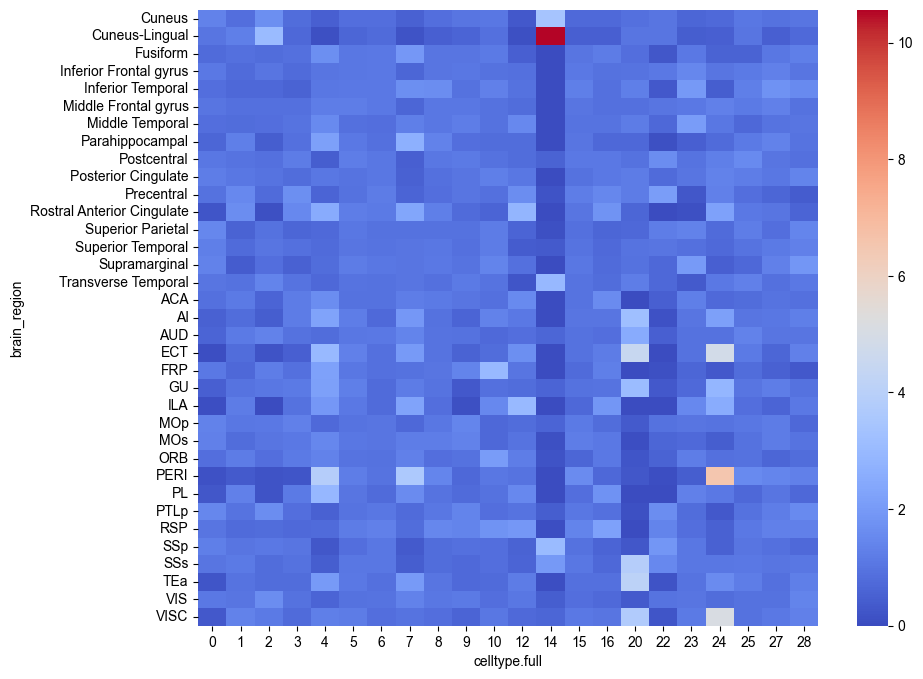

In [25]:
tmpdf = adata_bink_love.obs.copy()
tmpdf['brain_region'] = [lut_h_dissection_region[x] if isinstance(x,str) and x.find('Human')!=-1 else x for x in tmpdf['brain_region']]
tmpdf['count']=1
df_pivot_leiden_ori = pd.pivot_table(tmpdf,values='count',index=['species','brain_region'],columns='celltype.full',aggfunc='sum',observed=True,fill_value=0).astype(float)
df_pivot_leiden_ori = df_pivot_leiden_ori.sort_index()
print(df_pivot_leiden_ori.shape)

thresh_ratio = 0.001

print('h',np.sum(tmpdf['species']=='human')*thresh_ratio)
print('m',np.sum(tmpdf['species']=='mouse')*thresh_ratio)

df_pivot_leiden_ori = df_pivot_leiden_ori[df_pivot_leiden_ori.loc[['human']].sum(axis=0)[df_pivot_leiden_ori.loc[['human']].sum(axis=0)>np.sum(tmpdf['species']=='human')*thresh_ratio].index]
df_pivot_leiden_ori = df_pivot_leiden_ori[df_pivot_leiden_ori.loc[['mouse']].sum(axis=0)[df_pivot_leiden_ori.loc[['mouse']].sum(axis=0)>np.sum(tmpdf['species']=='mouse')*thresh_ratio].index]
print(df_pivot_leiden_ori.shape)
# df_pivot_leiden_ori.to_csv(r'G:\data\transcriptome\MERFISH\homo_similarity_yzx.csv')


from scipy.stats import chi2_contingency
chi2_h,p_h,dof_h,expected_h =chi2_contingency(df_pivot_leiden_ori.loc['human'].values)
Ro_e_h = df_pivot_leiden_ori.loc['human']/expected_h
row_sort_idx_h = np.argsort(Ro_e_h)
chi2_m,p_m,dof_m,expected_m =chi2_contingency(df_pivot_leiden_ori.loc['mouse'].values)
Ro_e_m = df_pivot_leiden_ori.loc['mouse']/expected_m
row_sort_idx_m = np.argsort(Ro_e_m)
Ro_e = pd.concat([Ro_e_h,Ro_e_m])
row_sort_idx = np.vstack([row_sort_idx_h,row_sort_idx_m])
plt.figure(figsize=(10,8))
sns.heatmap(Ro_e,cmap='coolwarm',)
plt.show()



In [26]:
def jaccard_similarity(list1, list2):
    intersection = len(list(set(list1).intersection(list2)))
    union = (len(set(list1)) + len(set(list2))) - intersection
    return float(intersection) / union

def generate_JI_matrix(row_sort_idx,topn):
    JI_matrix = np.zeros((row_sort_idx.shape[0],row_sort_idx.shape[0]))
    for i in range(row_sort_idx.shape[0]):
        arr1 = row_sort_idx[i][:topn]
        for j in range(row_sort_idx.shape[0]):
            arr2 = row_sort_idx[j][:topn]
            JI = jaccard_similarity(arr1,arr2)
            JI_matrix[i,j] = JI
    return JI_matrix


In [27]:
def get_rank(arr,target,ascending=True):
    if ascending:
        tmpsort = np.argsort(arr)
    else:
        tmpsort = np.argsort(arr)[::-1]
    sameflag = False
    rank = 0
    for j in range(len(tmpsort)):
        tmpidx = tmpsort[j]
        tmpcol = d_mat.columns[tmpidx]
        if j>=1:
            if arr[tmpsort[j-1]]==arr[tmpidx]:
                sameflag=True
            else:
                sameflag=False
        if not sameflag:
            rank = j
        if tmpcol == target:
            break
            
    return rank

In [28]:
human_to_mouse = {
    'Rostral Anterior Cingulate': ['ACA'],
    # 'Posterior Cingulate': ['RSP'],
    'Precentral': ['MOp'],
    'Postcentral': ['SSp'],
    'Superior Parietal': ['PTLp'],
    'Superior Temporal': ['AUD'],
    'Parahippocampal': ['PERI'],
    # 'Temporal Lobe': ['AUD-TEa-PERI-ECT'],
    'Cuneus': ['VIS'],
    # 'Cuneus-Lingual': ['VIS'],
    'Transverse Temporal': ['AUD'],
    # 'OL':['OL'],
    # 'FL':['FL'],
    # 'TL':['TL'],
    # 'PL':['PL'],
    # 'CC':['CC'],
}

mouse_to_human = {
    'ACA': ['Rostral Anterior Cingulate'],
    'PL-ILA-ORB': ['Inferior Frontal gyrus'],
    'MOp': ['Precentral'],
    'SSp': ['Postcentral'],
    'PTLp': ['Superior Parietal'],
    'AUD': [
        'Superior Temporal',
        'Transverse Temporal'
    ],
    'PERI': ['Parahippocampal'],
    'VIS': ['Cuneus'],
    # 'OL':['OL'],
    # 'FL':['FL'],
    # 'TL':['TL'],
    # 'PL':['PL'],
    # 'CC':['CC'],
    
}

lut_human_full_abbr = {
    'Rostral Anterior Cingulate': 'rACC',
    'Posterior Cingulate': 'PCC',
    'Inferior Frontal gyrus': 'IFG',
    'Precentral': 'PrCG',
    'Postcentral': 'PoCG',
    'Superior Parietal': 'SPL',
    'Superior Temporal': 'STG',
    'Middle Temporal': 'MTG',
    'Inferior Temporal': 'ITG',
    'Parahippocampal': 'PHG',
    'Fusiform': 'FuG',
    'Temporal Lobe': 'TL',
    'Cuneus': 'Cun',
    'Cuneus-Lingual': 'Cun-LiG',
    'Transverse Temporal': 'TTG',
    'Middle Frontal gyrus': 'MFG',
    'Supramarginal': 'SMG',
    'OL':'OL',
    'FL':'FL',
    'TL':'TL',
    'PL':'PL',
    'CC':'CC',
}

5 17


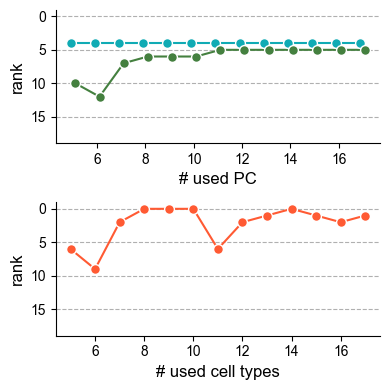

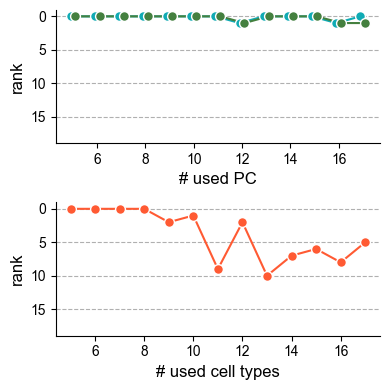

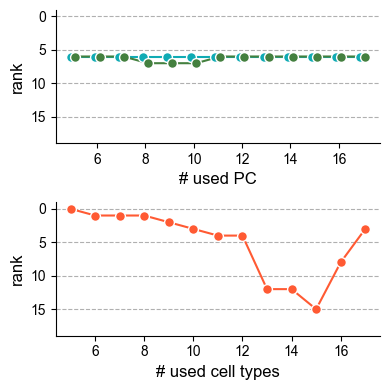

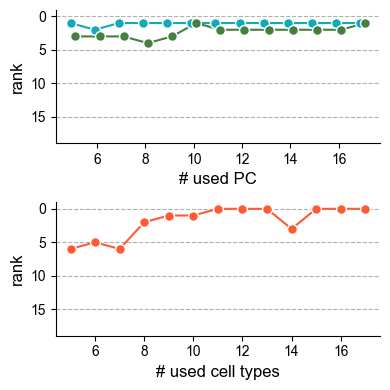

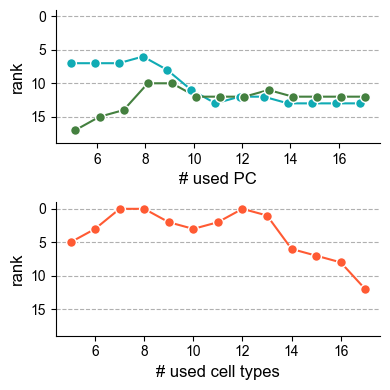

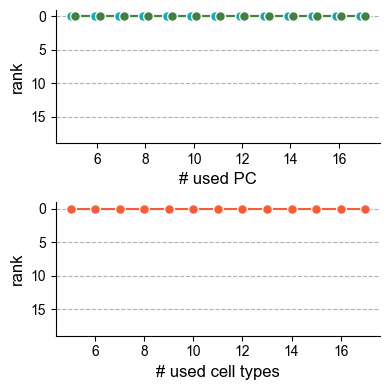

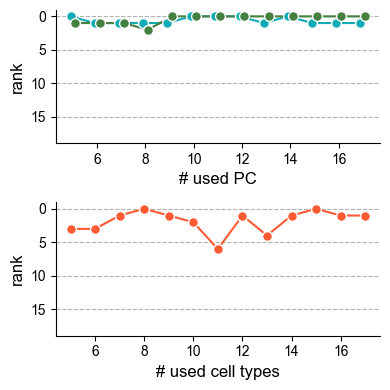

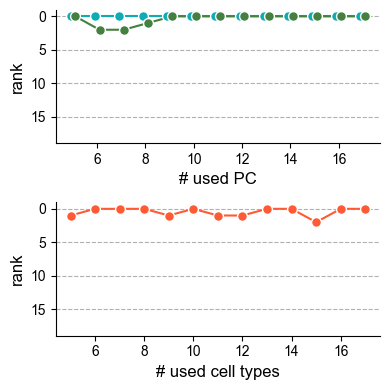

C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


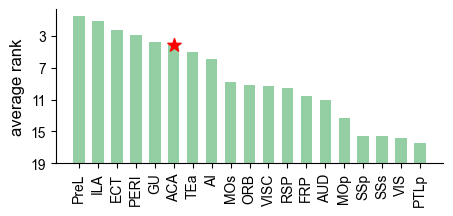

C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


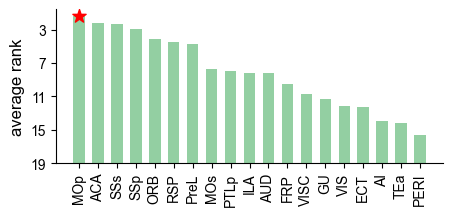

C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


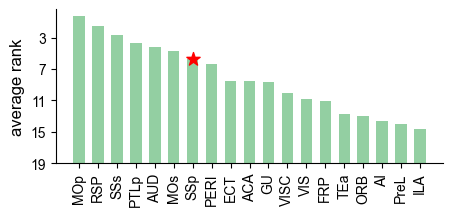

C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


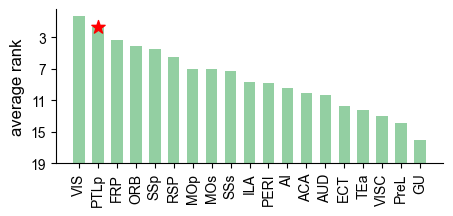

C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


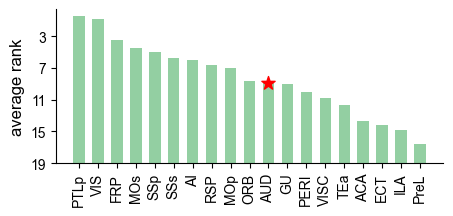

C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


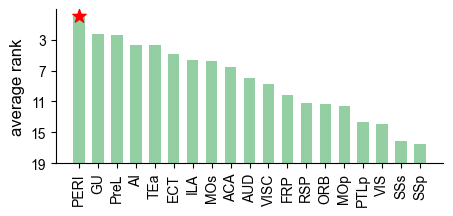

C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


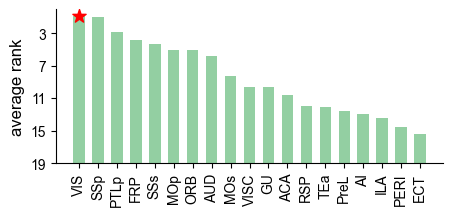

C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\593871688.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


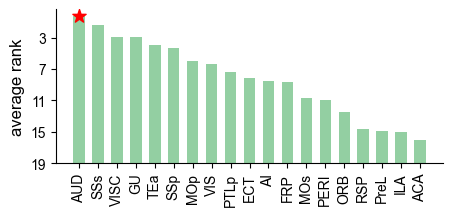

In [34]:
df_pivot_leiden = df_pivot_leiden_ori.copy()

len_h_index = df_pivot_leiden.loc['human'].shape[0]
len_m_index = df_pivot_leiden.loc['mouse'].shape[0]

df_pivot_leiden = df_pivot_leiden.div(df_pivot_leiden.sum(axis=1),axis=0)
df_pivot_leiden.loc[['human']] = (df_pivot_leiden.loc[['human']]-df_pivot_leiden.loc[['human']].mean(axis=0))/df_pivot_leiden.loc[['human']].std(axis=0)
df_pivot_leiden.loc[['mouse']] = (df_pivot_leiden.loc[['mouse']]-df_pivot_leiden.loc[['mouse']].mean(axis=0))/df_pivot_leiden.loc[['mouse']].std(axis=0)
df_pivot_leiden = df_pivot_leiden.dropna(how='any',axis=1)

npc_90 = PCA(0.75, random_state=821).fit_transform(df_pivot_leiden.values).shape[1]
npc_99 = PCA(0.99, random_state=821).fit_transform(df_pivot_leiden.values).shape[1]
print(npc_90, npc_99)

leiden_cluster_num = df_pivot_leiden_ori.shape[1]
lineplot_source_all = []
final_ranks = [[],[],[]]
ctpairs = []
for k in human_to_mouse:
    vlist = human_to_mouse[k]
    if k not in df_pivot_leiden_ori.loc['human'].index: continue
    for v in vlist: 
        namepair = [k,v]
        ctpairs.append(namepair)
        rank_matrix = np.zeros((npc_99+1-npc_90, df_pivot_leiden_ori.loc['mouse'].shape[0],2))
        rank_matrix_JI = np.zeros((npc_99+1-npc_90, df_pivot_leiden_ori.loc['mouse'].shape[0],1))
        for i,n_comp in enumerate(range(npc_90,npc_99+1)):
            
            pca = PCA(n_comp, random_state=821, svd_solver='full')
            df_pivot_leiden_pca = pd.DataFrame(pca.fit_transform(df_pivot_leiden.values),index=df_pivot_leiden.index)

            d_mat = pairwise_distances(df_pivot_leiden_pca.iloc[0:df_pivot_leiden_pca.loc['human'].shape[0]],df_pivot_leiden_pca.iloc[df_pivot_leiden_pca.loc['human'].shape[0]:],metric='cosine')
            d_mat = pd.DataFrame(d_mat,index=df_pivot_leiden_pca.loc['human'].index,columns=df_pivot_leiden_pca.loc['mouse'].index)
            rank1 = get_rank(d_mat.loc[k].values,v)
            # rank1 = list(d_mat.columns[np.argsort(d_mat.loc[k].values)]).index(v)
            for j in range(d_mat.shape[1]):
                final_ranks[0].append(get_rank(d_mat.loc[k].values, d_mat.columns[j]))

            d_mat = df_pivot_leiden_pca.T.corr()
            d_mat = pd.DataFrame(d_mat.loc['human','mouse'].values,index=df_pivot_leiden_pca.loc['human'].index,columns=df_pivot_leiden_pca.loc['mouse'].index)
            rank2 = get_rank(d_mat.loc[k].values, v, ascending=False)
            # rank2 = list(d_mat.columns[np.argsort(d_mat.loc[k].values)[::-1]]).index(v)
            for j in range(d_mat.shape[1]):
                final_ranks[1].append(get_rank(d_mat.loc[k].values, d_mat.columns[j], ascending=False))

            rank_matrix[i,rank1,0] = 1
            rank_matrix[i,rank2,1] = 1
            
        for i,used_cluster_num in enumerate(range(npc_90,npc_99+1)):
            d_mat = generate_JI_matrix(row_sort_idx,used_cluster_num)[0:df_pivot_leiden.loc['human'].shape[0],df_pivot_leiden.loc['human'].shape[0]:]
            d_mat = pd.DataFrame(d_mat,index=df_pivot_leiden.loc['human'].index,columns=df_pivot_leiden.loc['mouse'].index)
            rank3 = get_rank(d_mat.loc[k].values, v, ascending=False)
            for j in range(d_mat.shape[1]):
                final_ranks[2].append(get_rank(d_mat.loc[k].values, d_mat.columns[j], ascending=False))
            rank_matrix_JI[i,rank3,0] = 1
            

        fig,axs = plt.subplots(2,1,figsize=(4,4),tight_layout=True)
        axs[0].plot(np.arange(npc_90,npc_99+1)-0.1,[np.argwhere(x==1).flatten()[0] for x in rank_matrix[:,:,0]],color=np.array([16,171,180])/255,label='cosine',zorder=11)
        axs[0].plot(np.arange(npc_90,npc_99+1)+0.1,[np.argwhere(x==1).flatten()[0] for x in rank_matrix[:,:,1]],color=np.array([68,128,63])/255,label='Corr',zorder=11)
        axs[1].plot(np.arange(npc_90,npc_99+1),[np.argwhere(x==1).flatten()[0] for x in rank_matrix_JI[:,:,0]],color=np.array([255,90,51])/255,label='JI',zorder=11)
        
        axs[0].scatter(np.arange(npc_90,npc_99+1)-0.1,[np.argwhere(x==1).flatten()[0] for x in rank_matrix[:,:,0]],color=np.array([16,171,180])/255,edgecolors='white',s=50,lw=1,zorder=12)
        axs[0].scatter(np.arange(npc_90,npc_99+1)+0.1,[np.argwhere(x==1).flatten()[0] for x in rank_matrix[:,:,1]],color=np.array([68,128,63])/255,edgecolors='white',s=50,lw=1,zorder=12)
        axs[1].scatter(np.arange(npc_90,npc_99+1),[np.argwhere(x==1).flatten()[0] for x in rank_matrix_JI[:,:,0]],color=np.array([255,90,51])/255,edgecolors='white',s=50,lw=1,zorder=12)
        
        # axs[0].set_title(namepair)
        for ax in axs:
            # ax.legend(loc=(1.01,0.5))
            ax.legend().set_visible(False)
            ax.set_ylabel('rank',fontsize=12)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(axis='y',ls='--')
            ax.set_ylim(0-0.05*len_m_index,len_m_index-1+0.05*len_m_index)
            ax.xaxis.set_major_locator(MaxNLocator(integer=True,nbins='auto'))
            ax.yaxis.set_major_locator(MaxNLocator(integer=True,nbins='auto'))
            ax.invert_yaxis()
        axs[0].set_xlabel('# used PC',fontsize=12)
        axs[1].set_xlabel('# used cell types',fontsize=12)
        plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\h_to_m\metric_rank_{k}_{v}.png', bbox_inches='tight', dpi=500)
        plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\h_to_m\metric_rank_{k}_{v}.svg', bbox_inches='tight', dpi=500)
        plt.show()

        rank_cosine_plot = [np.argwhere(x == 1).flatten()[0] for x in rank_matrix[:, :, 0]]
        rank_corr_plot = [np.argwhere(x == 1).flatten()[0] for x in rank_matrix[:, :, 1]]
        rank_ji_plot = [np.argwhere(x == 1).flatten()[0] for x in rank_matrix_JI[:, :, 0]]

        df_lineplot_one_pair = pd.DataFrame({
            'human_region': k,
            'mouse_region': v,
            'nPCs': np.arange(npc_90, npc_99 + 1),
            'cosine_rank': rank_cosine_plot,
            'corr_rank': rank_corr_plot,
            'JI_rank': rank_ji_plot,
        })

        lineplot_source_all.append(df_lineplot_one_pair)

df_lineplot_source = pd.concat(lineplot_source_all, ignore_index=True)

df_lineplot_source.to_csv(
    r'E:\ZhixiYun\Projects\fMOST_atlas\Tables\source_data\Fig_4D_22.csv',
    index=False
)

source_rank_all = []
for i in range(len(ctpairs)):
    # for j in range(len(final_ranks)):
    final_rank1 = np.array(final_ranks[:2]).mean(axis=0).reshape(len(ctpairs), -1, df_pivot_leiden.loc['mouse'].shape[0])[i]
    final_rank2 = np.array(final_ranks[2]).reshape(len(ctpairs), -1, df_pivot_leiden.loc['mouse'].shape[0])[i]
    final_rank = np.vstack([final_rank1,final_rank1,final_rank2])


    fig,ax = plt.subplots(1,1,figsize=(5,2))
    final_rank_mean = np.mean(final_rank, axis=0)

    final_rank_mean_sort_idx = np.argsort(final_rank_mean)
    gt = np.argwhere(df_pivot_leiden.loc['mouse'].index==ctpairs[i][1]).flatten()[0]
    
    sns.barplot(x=np.arange(len(final_rank_mean)),y=len(df_pivot_leiden.loc['mouse'].index)-final_rank_mean[final_rank_mean_sort_idx],ax=ax,width=0.6,color=np.array([137,217,157])/255.0,)
    ax.set_xticklabels([x if x!='PL' else 'PreL' for x in df_pivot_leiden.loc['mouse'].index[final_rank_mean_sort_idx]],rotation=90)
    ax.scatter(np.argwhere(final_rank_mean_sort_idx==gt).flatten()[0],len(df_pivot_leiden.loc['mouse'].index)-final_rank_mean[gt],marker='*',s=100,color='red')
    # ax.set_title(str(ctpairs[i]))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel('average rank',fontsize=12)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True,nbins='auto'))
    ax.set_yticklabels([str(len(df_pivot_leiden.loc['mouse'].index)-int(x.get_text())) for x in ax.get_yticklabels()])
    plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\h_to_m\mean_rank_{ctpairs[i][0]}_{ctpairs[i][1]}.png', bbox_inches='tight', dpi=500)
    plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\h_to_m\mean_rank_{ctpairs[i][0]}_{ctpairs[i][1]}.svg', bbox_inches='tight', dpi=500)
    plt.show()


    source_rank_all.append(pd.DataFrame({
        'final_rank': final_rank_mean,
        'human_region': [ctpairs[i][0]]*len(df_pivot_leiden.loc['mouse']),
        'mouse_region': df_pivot_leiden.loc['mouse'].index,
    }).sort_values('final_rank'))

df_sourcedata = pd.concat(source_rank_all, ignore_index=True)
df_sourcedata.to_csv(rf'E:\ZhixiYun\Projects\fMOST_atlas\Tables\source_data\Fig_4D_21.csv', index=False)

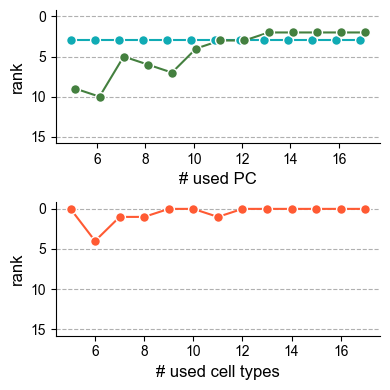

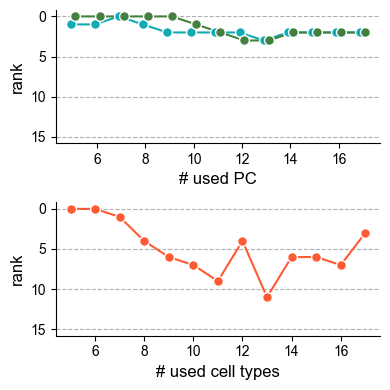

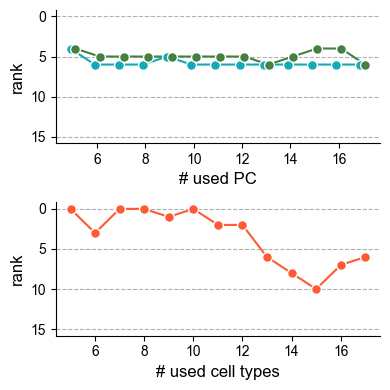

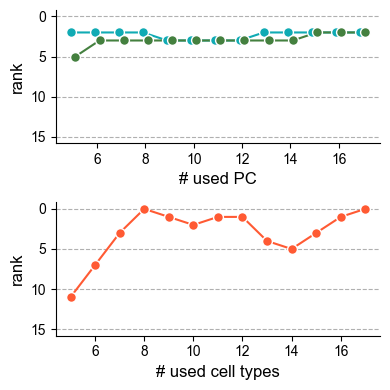

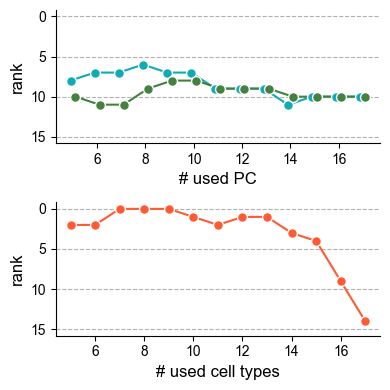

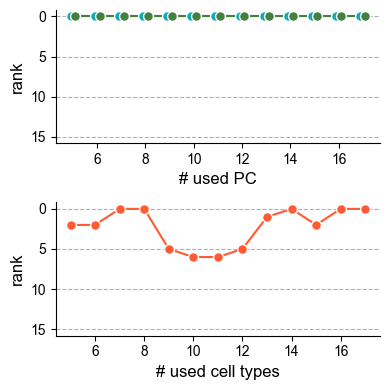

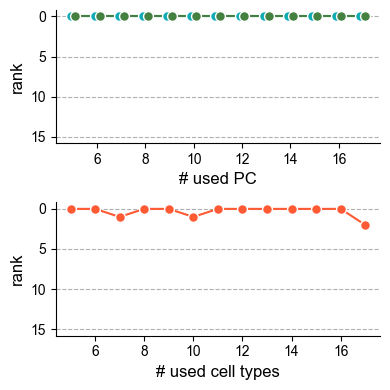

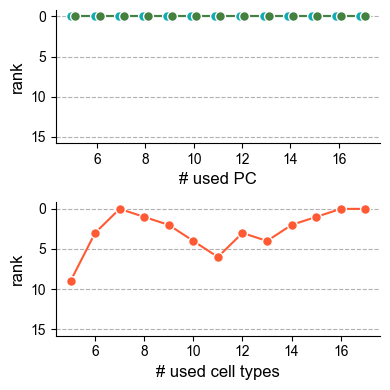

C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


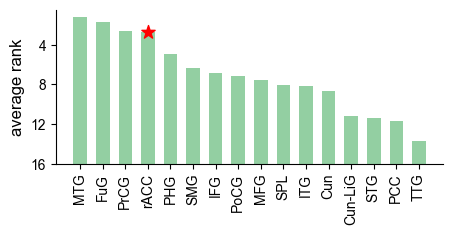

C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


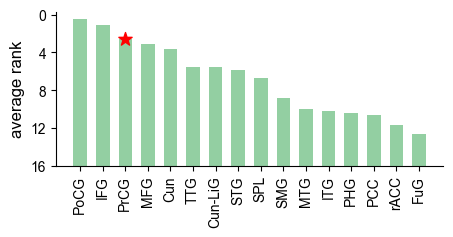

C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


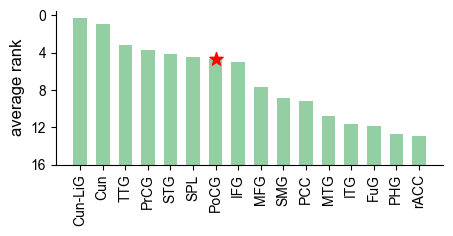

C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


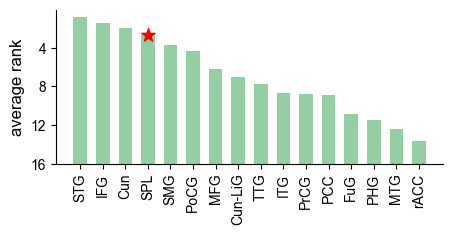

C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


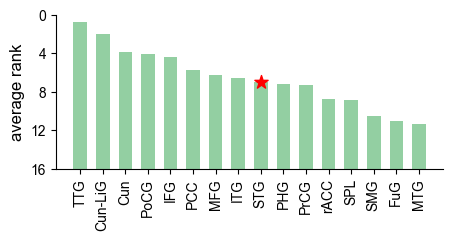

C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


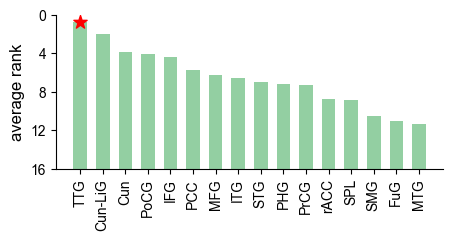

C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


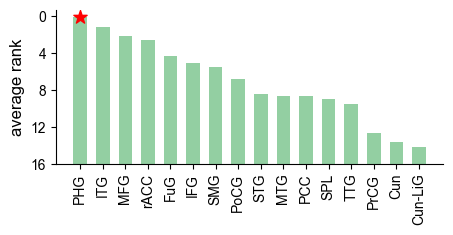

C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:119: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
C:\Users\user\AppData\Local\Temp\ipykernel_21004\1992190901.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])


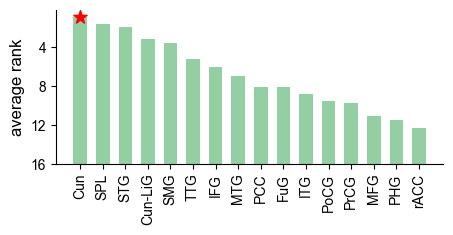

In [33]:

df_pivot_leiden = df_pivot_leiden_ori.copy()

df_pivot_leiden = df_pivot_leiden.div(df_pivot_leiden.sum(axis=1),axis=0)
df_pivot_leiden.loc[['human']] = (df_pivot_leiden.loc[['human']]-df_pivot_leiden.loc[['human']].mean(axis=0))/df_pivot_leiden.loc[['human']].std(axis=0)
df_pivot_leiden.loc[['mouse']] = (df_pivot_leiden.loc[['mouse']]-df_pivot_leiden.loc[['mouse']].mean(axis=0))/df_pivot_leiden.loc[['mouse']].std(axis=0)
df_pivot_leiden = df_pivot_leiden.dropna(how='any',axis=1)

npc_90 = PCA(0.75, random_state=821).fit_transform(df_pivot_leiden.values).shape[1]
npc_99 = PCA(0.99, random_state=821).fit_transform(df_pivot_leiden.values).shape[1]


leiden_cluster_num = df_pivot_leiden_ori.shape[1]
lineplot_source_all = []
final_ranks = [[],[],[]]
ctpairs = []
for k in mouse_to_human:
    vlist = mouse_to_human[k]
    if k not in df_pivot_leiden_ori.loc['mouse'].index: continue
    for v in vlist: 
        namepair = [k,v]
        ctpairs.append(namepair)
        rank_matrix = np.zeros((npc_99+1-npc_90, df_pivot_leiden_ori.loc['human'].shape[0],2))
        rank_matrix_JI = np.zeros((npc_99+1-npc_90, df_pivot_leiden_ori.loc['human'].shape[0],1))
        for i,n_comp in enumerate(range(npc_90,npc_99+1)):
            
            pca = PCA(n_comp, random_state=821)
            df_pivot_leiden_pca = pd.DataFrame(pca.fit_transform(df_pivot_leiden.values),index=df_pivot_leiden.index)

            d_mat = pairwise_distances(df_pivot_leiden_pca.iloc[0:df_pivot_leiden_pca.loc['human'].shape[0]],df_pivot_leiden_pca.iloc[df_pivot_leiden_pca.loc['human'].shape[0]:],metric='cosine')
            d_mat = pd.DataFrame(d_mat,index=df_pivot_leiden_pca.loc['human'].index,columns=df_pivot_leiden_pca.loc['mouse'].index).T
            rank1 = get_rank(d_mat.loc[k].values,v)
            # rank1 = list(d_mat.columns[np.argsort(d_mat.loc[k].values)]).index(v)
            for j in range(d_mat.shape[1]):
                final_ranks[0].append(get_rank(d_mat.loc[k].values, d_mat.columns[j]))

            d_mat = df_pivot_leiden_pca.T.corr()
            d_mat = pd.DataFrame(d_mat.loc['human','mouse'].values,index=df_pivot_leiden_pca.loc['human'].index,columns=df_pivot_leiden_pca.loc['mouse'].index).T
            rank2 = get_rank(d_mat.loc[k].values, v, ascending=False)
            # rank2 = list(d_mat.columns[np.argsort(d_mat.loc[k].values)[::-1]]).index(v)
            for j in range(d_mat.shape[1]):
                final_ranks[1].append(get_rank(d_mat.loc[k].values, d_mat.columns[j], ascending=False))

            rank_matrix[i,rank1,0] = 1
            rank_matrix[i,rank2,1] = 1
            
        for i,used_cluster_num in enumerate(range(npc_90,npc_99+1)):
            d_mat = generate_JI_matrix(row_sort_idx,used_cluster_num)[0:df_pivot_leiden.loc['human'].shape[0],df_pivot_leiden.loc['human'].shape[0]:]
            d_mat = pd.DataFrame(d_mat,index=df_pivot_leiden.loc['human'].index,columns=df_pivot_leiden.loc['mouse'].index).T
            rank3 = get_rank(d_mat.loc[k].values, v, ascending=False)
            for j in range(d_mat.shape[1]):
                final_ranks[2].append(get_rank(d_mat.loc[k].values, d_mat.columns[j], ascending=False))
            rank_matrix_JI[i,rank3,0] = 1
            

        fig,axs = plt.subplots(2,1,figsize=(4,4),tight_layout=True)
        axs[0].plot(np.arange(npc_90,npc_99+1)-0.1,[np.argwhere(x==1).flatten()[0] for x in rank_matrix[:,:,0]],color=np.array([16,171,180])/255,label='cosine',zorder=11)
        axs[0].plot(np.arange(npc_90,npc_99+1)+0.1,[np.argwhere(x==1).flatten()[0] for x in rank_matrix[:,:,1]],color=np.array([68,128,63])/255,label='Corr',zorder=11)
        axs[1].plot(np.arange(npc_90,npc_99+1),[np.argwhere(x==1).flatten()[0] for x in rank_matrix_JI[:,:,0]],color=np.array([255,90,51])/255,label='JI',zorder=11)
        
        axs[0].scatter(np.arange(npc_90,npc_99+1)-0.1,[np.argwhere(x==1).flatten()[0] for x in rank_matrix[:,:,0]],color=np.array([16,171,180])/255,edgecolors='white',s=50,lw=1,zorder=12)
        axs[0].scatter(np.arange(npc_90,npc_99+1)+0.1,[np.argwhere(x==1).flatten()[0] for x in rank_matrix[:,:,1]],color=np.array([68,128,63])/255,edgecolors='white',s=50,lw=1,zorder=12)
        axs[1].scatter(np.arange(npc_90,npc_99+1),[np.argwhere(x==1).flatten()[0] for x in rank_matrix_JI[:,:,0]],color=np.array([255,90,51])/255,edgecolors='white',s=50,lw=1,zorder=12)
        
        # axs[0].set_title(namepair)
        for ax in axs:
            # ax.legend(loc=(1.01,0.5))
            ax.legend().set_visible(False)
            ax.set_ylabel('rank',fontsize=12)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(axis='y',ls='--')
            ax.set_ylim(0-0.05*len_h_index,len_h_index-1+0.05*len_h_index)
            ax.xaxis.set_major_locator(MaxNLocator(integer=True,nbins='auto'))
            ax.yaxis.set_major_locator(MaxNLocator(integer=True,nbins='auto'))
            ax.invert_yaxis()
        axs[0].set_xlabel('# used PC',fontsize=12)
        axs[1].set_xlabel('# used cell types',fontsize=12)
        plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\m_to_h\metric_rank_{k}_{v}.png', bbox_inches='tight', dpi=500)
        plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\m_to_h\metric_rank_{k}_{v}.svg', bbox_inches='tight', dpi=500)
        plt.show()


        rank_cosine_plot = [np.argwhere(x == 1).flatten()[0] for x in rank_matrix[:, :, 0]]
        rank_corr_plot = [np.argwhere(x == 1).flatten()[0] for x in rank_matrix[:, :, 1]]
        rank_ji_plot = [np.argwhere(x == 1).flatten()[0] for x in rank_matrix_JI[:, :, 0]]

        df_lineplot_one_pair = pd.DataFrame({
            'mouse_region': k,
            'human_region': v,
            'nPCs': np.arange(npc_90, npc_99 + 1),
            'cosine_rank': rank_cosine_plot,
            'corr_rank': rank_corr_plot,
            'JI_rank': rank_ji_plot,
        })

        lineplot_source_all.append(df_lineplot_one_pair)

df_lineplot_source = pd.concat(lineplot_source_all, ignore_index=True)

df_lineplot_source.to_csv(
    r'E:\ZhixiYun\Projects\fMOST_atlas\Tables\source_data\Fig_4D_12.csv',
    index=False
)

source_rank_all = []
for i in range(len(ctpairs)):
    # for j in range(len(final_ranks)):
    final_rank1 = np.array(final_ranks[:2]).mean(axis=0).reshape(len(ctpairs), -1, df_pivot_leiden.loc['human'].shape[0])[i]
    final_rank2 = np.array(final_ranks[2]).reshape(len(ctpairs), -1, df_pivot_leiden.loc['human'].shape[0])[i]
    final_rank = np.vstack([final_rank1,final_rank1,final_rank2])

    fig,ax = plt.subplots(1,1,figsize=(5,2))
    final_rank_mean = np.mean(final_rank, axis=0)

    final_rank_mean_sort_idx = np.argsort(final_rank_mean)
    gt = np.argwhere(df_pivot_leiden.loc['human'].index==ctpairs[i][1]).flatten()[0]
    
    sns.barplot(x=np.arange(len(final_rank_mean)),y=len(df_pivot_leiden.loc['human'].index)-final_rank_mean[final_rank_mean_sort_idx],ax=ax,width=0.6,color=np.array([137,217,157])/255.0,)
    ax.set_xticklabels(df_pivot_leiden.loc['human'].index[final_rank_mean_sort_idx],rotation=90)
    ax.scatter(np.argwhere(final_rank_mean_sort_idx==gt).flatten()[0],len(df_pivot_leiden.loc['human'].index)-final_rank_mean[gt],marker='*',s=100,color='red')
    # ax.set_title(str(ctpairs[i]))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel('average rank',fontsize=12)
    ax.set_xticklabels([lut_human_full_abbr[x.get_text()] for x in ax.get_xticklabels()])
    ax.yaxis.set_major_locator(MaxNLocator(integer=True,nbins='auto'))
    ax.set_yticklabels([str(len(df_pivot_leiden.loc['human'].index)-int(x.get_text())) for x in ax.get_yticklabels()])
    plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\m_to_h\mean_rank_{ctpairs[i][0]}_{ctpairs[i][1]}.png', bbox_inches='tight', dpi=500)
    plt.savefig(rf'E:\ZhixiYun\Projects\fMOST_atlas\Figures\Homologous\gene\MERFISH\m_to_h\mean_rank_{ctpairs[i][0]}_{ctpairs[i][1]}.svg', bbox_inches='tight', dpi=500)
    plt.show()
    
    
    source_rank_all.append(pd.DataFrame({
        'final_rank': final_rank_mean,
        'mouse_region': [ctpairs[i][0]]*len(df_pivot_leiden.loc['human']),
        'human_region': df_pivot_leiden.loc['human'].index,
    }).sort_values('final_rank'))

df_sourcedata = pd.concat(source_rank_all, ignore_index=True)
df_sourcedata.to_csv(rf'E:\ZhixiYun\Projects\fMOST_atlas\Tables\source_data\Fig_4D_11.csv', index=False)